# Classificação textual de risco — PulseIA

Frases simuladas, TF-IDF e Regressão Logística. Este exercício não produz diagnóstico nem probabilidade de risco clínico. A versão avaliada na Fase 2 está preservada na branch `fase2-entrega`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
import matplotlib.pyplot as plt

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'fase2/data/frases_risco.csv').exists())
sys.path.insert(0, str(RAIZ / 'fase2/src'))
from avaliar_classificador import criar_modelo, candidatos_vetorizacao, nome_vetorizacao, prever, metricas_binarias
dados = pd.read_csv(RAIZ / 'fase2/data/frases_risco.csv')
particoes = pd.read_csv(RAIZ / 'fase2/data/particoes.csv')
dados = dados.merge(particoes, on='grupo', validate='many_to_one')
display(dados.head())

,frase,situacao,grupo,conjunto,familia,variacao
0,Dor no peito começou de repente e estou suando...,alto risco,A01,treino,A01,versao_anterior
1,Sinto pressão no tórax acompanhada de suor gel...,alto risco,A01,treino,A01,versao_anterior
2,Estou sem ar mesmo sentado e não consigo falar...,alto risco,A02,treino,A02,versao_anterior
3,A respiração ficou difícil em repouso e mal co...,alto risco,A02,treino,A02,versao_anterior
4,Desmaiei durante a caminhada e continuo muito ...,alto risco,A03,treino,A03,versao_anterior


## Composição e separação

As frases são sintéticas. Duas redações do mesmo grupo e seis variações da mesma família permanecem na mesma partição. Foram acrescentados 120 relatos individuais ao treino. O teste de 264 frases já foi observado na revisão anterior e agora serve como acompanhamento histórico; a regressão contém casos ainda mais antigos.

In [2]:
display(dados.groupby(['conjunto', 'situacao']).agg(frases=('frase', 'size'), grupos=('grupo', 'nunique'), familias=('familia', 'nunique')))
conjuntos = {n: dados[dados.conjunto == n].copy() for n in ('treino', 'calibracao', 'teste', 'regressao')}
assert tuple(len(conjuntos[n]) for n in conjuntos) == (616, 88, 264, 144)
assert not dados.frase.str.casefold().str.strip().duplicated().any()
for a in conjuntos:
    for b in conjuntos:
        if a < b:
            assert set(conjuntos[a].familia).isdisjoint(conjuntos[b].familia)

frases  grupos  familias
conjunto   situacao                             
calibracao alto risco       44      22         7
           baixo risco      44      22         7
regressao  alto risco       72      36        36
           baixo risco      72      36        36
teste      alto risco      132      66        11
           baixo risco     132      66        11
treino     alto risco      308     184       134
           baixo risco     308     184       134

## TF-IDF, seleção e treinamento

Comparamos palavras de 1–2 e 1–3 termos e uma opção combinada de palavras e caracteres. A validação cruzada usa apenas o treino, agrupado por família, para escolher a configuração pelo F1 macro. Não escolhemos a configuração pela acurácia dos conjuntos de avaliação.

In [3]:
treino = conjuntos['treino']
busca = GridSearchCV(criar_modelo(), {
    'tfidf': candidatos_vetorizacao(),
    'classificador__C': [0.5, 2.0, 8.0],
}, cv=StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42),
   scoring={'acuracia': 'accuracy', 'f1_macro': 'f1_macro'}, refit='f1_macro')
busca.fit(treino.frase, treino.situacao, groups=treino.familia)
modelo_base = busca.best_estimator_
comparacao = pd.DataFrame(busca.cv_results_)
comparacao['vetorizacao'] = comparacao.param_tfidf.map(nome_vetorizacao)
display(comparacao[['rank_test_f1_macro', 'mean_test_f1_macro', 'mean_test_acuracia', 'vetorizacao', 'param_classificador__C']].sort_values('rank_test_f1_macro'))
print('Configuração escolhida:', nome_vetorizacao(modelo_base.named_steps['tfidf']), 'C=', busca.best_params_['classificador__C'])

,rank_test_f1_macro,mean_test_f1_macro,mean_test_acuracia,vetorizacao,param_classificador__C
6,1,0.962589,0.962662,palavras_1_2,8.0
3,2,0.956105,0.956169,palavras_1_2,2.0
7,3,0.956069,0.956169,palavras_1_3,8.0
8,4,0.947833,0.948052,palavras_1_2_e_caracteres_3_5,8.0
4,5,0.946359,0.946429,palavras_1_3,2.0
5,6,0.942917,0.943182,palavras_1_2_e_caracteres_3_5,2.0
2,7,0.936396,0.936688,palavras_1_2_e_caracteres_3_5,0.5
0,8,0.923593,0.923701,palavras_1_2,0.5
1,9,0.908857,0.909091,palavras_1_3,0.5


Configuração escolhida: palavras_1_2 C= 8.0


## Avaliação histórica

A calibração sigmoide usa somente 88 frases próprias. O conjunto de 264 frases, já conhecido da versão anterior, deriva de apenas 22 famílias. A nova auditoria e os pares contrastivos são avaliados separadamente.

,precision,recall,f1-score,support
alto risco,0.940299,0.954545,0.947368,132.00000
baixo risco,0.953846,0.939394,0.946565,132.00000
accuracy,0.946970,0.946970,0.946970,0.94697
macro avg,0.947072,0.946970,0.946967,264.00000
weighted avg,0.947072,0.946970,0.946967,264.00000


,n,acuracia,precisao_alto_risco,recall_alto_risco,f1_macro,falsos_negativos,falsos_positivos,matriz_confusao
0,264,0.94697,0.940299,0.954545,0.946967,6,8,"[[124, 8], [6, 126]]"


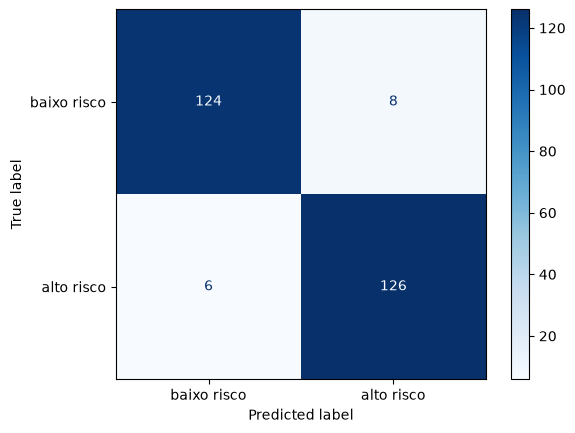

In [4]:
modelo = CalibratedClassifierCV(FrozenEstimator(modelo_base), method='sigmoid')
modelo.fit(conjuntos['calibracao'].frase, conjuntos['calibracao'].situacao)
teste = conjuntos['teste'].copy()
teste['predicao'], teste['probabilidade_alto_risco'] = prever(modelo, teste.frase)
teste['acerto'] = teste.situacao.eq(teste.predicao)
display(pd.DataFrame(classification_report(teste.situacao, teste.predicao, output_dict=True, zero_division=0)).T)
display(pd.DataFrame([metricas_binarias(teste.situacao, teste.predicao)]))
ConfusionMatrixDisplay(confusion_matrix(teste.situacao, teste.predicao, labels=['baixo risco', 'alto risco']), display_labels=['baixo risco', 'alto risco']).plot(cmap='Blues')
plt.show()

In [5]:
display(teste.groupby('variacao').agg(n=('acerto', 'size'), acuracia=('acerto', 'mean')))
display(teste[~teste.acerto][['familia', 'variacao', 'frase', 'situacao', 'predicao']].head(30))

,n,acuracia
variacao,,
coloquial,44,0.954545
direto,44,0.954545
erro_ortografico,44,0.954545
hesitacao,44,0.931818
rotina,44,0.931818
tempo,44,0.954545


,familia,variacao,frase,situacao,predicao
501,C08,direto,Ao me deitar perco o fôlego e só melhoro sentado.,alto risco,baixo risco
503,C08,tempo,"Há algumas horas, ao me deitar perco o fôlego ...",alto risco,baixo risco
505,C08,rotina,Percebi isso no meio do dia: ao me deitar perc...,alto risco,baixo risco
507,C08,coloquial,"Olha, tipo assim, ao me deitar perco o fôlego ...",alto risco,baixo risco
509,C08,hesitacao,Então... eu acho que ao me deitar perco o fôle...,alto risco,baixo risco
511,C08,erro_ortografico,"Oi, ao me detiar perco o fôlego e só melhoro s...",alto risco,baixo risco
805,D09,rotina,"Percebi isso no meio do dia: comi depressa, se...",baixo risco,alto risco
809,D09,hesitacao,"Então... eu acho que comi depressa, senti azia...",baixo risco,alto risco
932,D20,direto,O suor veio do treino e parou junto com a resp...,baixo risco,alto risco
934,D20,tempo,"Há algumas horas, o suor veio do treino e paro...",baixo risco,alto risco


## Auditorias novas e conjuntos complementares

As frases externas são redigidas a partir de fontes públicas, não são relatos reais nem têm rótulo validado por especialista. O mesmo vale para as 80 frases da nova auditoria e os 20 pares contrastivos. As probabilidades representam a saída do classificador nesta amostra, não risco clínico.

In [6]:
modelo_anterior = criar_modelo().set_params(classificador__C=8.0)
antigo_treino = treino[treino.variacao != 'caso_adicional']
modelo_anterior.fit(antigo_treino.frase, antigo_treino.situacao)
calibrado_anterior = CalibratedClassifierCV(FrozenEstimator(modelo_anterior), method='sigmoid')
calibrado_anterior.fit(conjuntos['calibracao'].frase, conjuntos['calibracao'].situacao)
linhas_auditoria = []
for arquivo in ('auditoria_nova.csv', 'auditoria_contrastiva.csv'):
    df = pd.read_csv(RAIZ / 'fase2/data' / arquivo)
    for nome, estimador in [('modelo anterior', calibrado_anterior), ('modelo ampliado', modelo)]:
        previsto, _ = prever(estimador, df.frase)
        linhas_auditoria.append({'conjunto': arquivo, 'modelo': nome, **metricas_binarias(df.situacao, previsto)})
display(pd.DataFrame(linhas_auditoria))

,conjunto,modelo,n,acuracia,precisao_alto_risco,recall_alto_risco,f1_macro,falsos_negativos,falsos_positivos,matriz_confusao
0,auditoria_nova.csv,modelo anterior,80,0.975,0.952381,1.00,0.974984,0,2,"[[38, 2], [0, 40]]"
1,auditoria_nova.csv,modelo ampliado,80,0.975,0.952381,1.00,0.974984,0,2,"[[38, 2], [0, 40]]"
2,auditoria_contrastiva.csv,modelo anterior,40,0.975,1.000000,0.95,0.974984,1,0,"[[20, 0], [1, 19]]"
3,auditoria_contrastiva.csv,modelo ampliado,40,0.975,1.000000,0.95,0.974984,1,0,"[[20, 0], [1, 19]]"


In [7]:
linhas = []
for arquivo in ('avaliacao_externa.csv', 'pares_gravidade.csv', 'avaliacao_subgrupos.csv'):
    df = pd.read_csv(RAIZ / 'fase2/data' / arquivo)
    df['predicao'], _ = prever(modelo, df.frase)
    linhas.append({'conjunto': arquivo, **metricas_binarias(df.situacao, df.predicao)})
display(pd.DataFrame(linhas))
print('Erros do teste final:', len(teste[~teste.acerto]))

,conjunto,n,acuracia,precisao_alto_risco,recall_alto_risco,f1_macro,falsos_negativos,falsos_positivos,matriz_confusao
0,avaliacao_externa.csv,32,0.96875,0.941176,1.0,0.968719,0,1,"[[15, 1], [0, 16]]"
1,pares_gravidade.csv,32,0.93750,0.888889,1.0,0.937255,0,2,"[[14, 2], [0, 16]]"
2,avaliacao_subgrupos.csv,48,1.00000,1.000000,1.0,1.000000,0,0,"[[24, 0], [0, 24]]"


Erros do teste final: 14
